# Program-first advanced analyses for temporal CC-Perturb-seq

This notebook generates exploratory, **program-first** analyses inspired by asynchronous-development and perturbation-convergence studies, adapted to the D0–D3 iPSC-EC differentiation Perturb-seq system.

The notebook intentionally keeps the main interpretation at the level of **expert-curated cNMF programs**, not Leiden/UMAP clusters.

Main analyses included:

1. **Target × curated program map** and source matrices
2. **Program-defined target fingerprints** using raw program effects, not subtracting calibrated quantities
3. **Lagged program-coupling network** across D1 → D2 → D3
4. **D2-to-D3 mediation / prediction-style analyses** without defining ad hoc branch scores
5. **Program-defined bottleneck proxy plots** using raw effects
6. **Program-level regulon / signature overlay** using top-loading genes and marker sets
7. **Program convergence analysis**: which regulator sets converge on which programs
8. **First-affected-day and persistence/transience analyses**
9. **Target module clustering, specificity, and asynchrony-like spread metrics**
10. Optional hooks for **neighborhood vulnerability maps** and **cross-screen concordance**

Notes:
- Program effects are read from the cNMF spreadsheet sheet `Perturbation Association 1`.
- Program annotations come from `curated_program_annotations.csv`, derived from the expert-checked annotation file.
- Outputs are written to `outputs_program_first_advanced/`.

In [1]:
# ==============================
# Configuration
# ==============================
from pathlib import Path
import os

# Main cNMF spreadsheet. Update this if needed.
CNMF_XLSX = Path('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx')

# If running outside Oak, set this to your local copy.
LOCAL_CANDIDATES = [
    Path('cNMF_50_0_2_032526_6co.xlsx'),
    Path('cNMF_50_0_2 032526_6co.xlsx'),
    Path('/mnt/data/cNMF_50_0_2_032526_6co.xlsx'),
    Path('/mnt/data/cNMF_50_0_2 032526_6co.xlsx'),
]
if not CNMF_XLSX.exists():
    for p in LOCAL_CANDIDATES:
        if p.exists():
            CNMF_XLSX = p
            break

ASSOC_SHEET = 'Perturbation Association 1'
SUMMARY_SHEET = 'Summary'
PROGRAM_ANNOTATION_CSV = Path('curated_program_annotations.csv')
if not PROGRAM_ANNOTATION_CSV.exists():
    PROGRAM_ANNOTATION_CSV = Path('/mnt/data/program_first_advanced_analyses_notebook/curated_program_annotations.csv')

OUTDIR = Path('outputs_program_first_advanced')
OUTDIR.mkdir(parents=True, exist_ok=True)

FDR_CUTOFF = 0.05
EFFECT_CUTOFF_FOR_LABELS = 0.25
MIN_ABS_R_FOR_NETWORK = 0.30
MIN_OVERLAP_TARGETS_FOR_CORR = 30

# Optional files. Leave None if unavailable.
NEIGHBORHOOD_ENRICHMENT_CSV = None  # e.g. Path('neighborhood_enrichment_selected_targets.csv')
NEIGHBORHOOD_COORDINATES_CSV = None # e.g. Path('panelAB_neighborhood_metadata.csv')
CUSTOM_SIGNATURES_CSV = None       # columns: signature, gene
CUSTOM_TARGET_SETS_CSV = None      # columns: target_set, target
GENOME_WIDE_SCREEN_CSV = None      # optional for cross-screen concordance

# Gene/pathway groups to highlight in selected plots.
TARGET_SETS_BUILTIN = {
    'Hippo/YAP': ['NF2','LATS2','SAV1','TAOK1','AMOTL2','WWC1','WWC2','MST1','STK4','STK3'],
    'BMP/TGF-SMAD': ['SMAD1','SMAD4','SMAD5','LEMD3','BMPR1A','ACVR2A','ACVR1B','ACVR2B','BMPR2','TGFBR1','TGFBR2'],
    'EC regulators': ['ETV2','KDR','ERG','FLI1','TAL1','SOX17','PECAM1','CDH5','VWF','ESAM','NOTCH1','DLL4'],
    'Notch/vascular': ['NOTCH1','NOTCH4','DLL4','JAG1','RBPJ','HEY1','HEY2','KDR','FLT1'],
    'Primitive streak/mesoderm': ['TBXT','MIXL1','EOMES','MESP1','HAND1','HAND2','CDX2','MSX1'],
    'PKC/stress': ['PRKCD','MAPK1','MAPK3','JUN','FOS','DUSP1','DUSP6'],
}

SELECTED_TARGETS_FOR_CARDS = [
    'NF2','LATS2','SAV1','TAOK1','AMOTL2',
    'SMAD1','SMAD4','SMAD5','LEMD3','BMPR1A','ACVR2A',
    'PRKCD','ETV2','KDR','ERG','FLI1','TAL1'
]

print('CNMF_XLSX:', CNMF_XLSX, 'exists:', CNMF_XLSX.exists())
print('Program annotation:', PROGRAM_ANNOTATION_CSV, 'exists:', PROGRAM_ANNOTATION_CSV.exists())
print('Output directory:', OUTDIR.resolve())

CNMF_XLSX: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx exists: True
Program annotation: curated_program_annotations.csv exists: True
Output directory: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/program_first_advanced_analyses_notebook_package/outputs_program_first_advanced


In [2]:
# ==============================
# Imports and helper functions
# ==============================
import re
import math
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist
from scipy.stats import hypergeom

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.9,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})


def pick_col(df, candidates, required=True, label='column'):
    lower = {str(c).lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    # fuzzy contains
    for c in df.columns:
        cl = str(c).lower()
        for cand in candidates:
            if cand.lower() in cl:
                return c
    if required:
        raise ValueError(f'Could not infer {label}. Tried: {candidates}. Available: {list(df.columns)}')
    return None


def normalize_day(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.upper().startswith('D'):
        m = re.search(r'(\d+)', s)
        return f'D{m.group(1)}' if m else s.upper()
    if s.lower().startswith('day'):
        m = re.search(r'(\d+)', s)
        return f'D{m.group(1)}' if m else s
    if re.fullmatch(r'\d+(\.0)?', s):
        return f'D{int(float(s))}'
    return s


def extract_program_id(x):
    if pd.isna(x):
        return np.nan
    s = str(x)
    m = re.search(r'(\d+)', s)
    return int(m.group(1)) if m else np.nan


def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    q = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    n = len(pv)
    if n == 0:
        return q
    order = np.argsort(pv)
    ranked = pv[order]
    adj = ranked * n / (np.arange(n) + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(adj, 1.0)
    q[ok] = out
    return q


def zscore_series(s):
    s = pd.Series(s, dtype=float)
    sd = s.std(ddof=0)
    if sd == 0 or np.isnan(sd):
        return s * 0
    return (s - s.mean()) / sd


def savefig(fig, stem, width=None, height=None):
    png = OUTDIR / f'{stem}.png'
    pdf = OUTDIR / f'{stem}.pdf'
    svg = OUTDIR / f'{stem}.svg'
    fig.savefig(png, dpi=350, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    fig.savefig(svg, bbox_inches='tight')
    print('saved:', png)
    print('saved:', pdf)
    print('saved:', svg)


def parse_gene_list(x):
    if pd.isna(x):
        return []
    parts = re.split(r'[;,/]|\s{2,}', str(x))
    genes = []
    for p in parts:
        # remove rank notes like HAND1 (6)
        p = re.sub(r'\(.*?\)', '', p).strip()
        p = p.replace('\xa0','').strip()
        if p and re.match(r'^[A-Za-z0-9_.-]+$', p):
            genes.append(p.upper())
    return list(dict.fromkeys(genes))


def fisher_overlap(k, K, n, N):
    # probability of >=k overlap; universe N; gene set size K; list size n
    if k <= 0 or any(pd.isna([k,K,n,N])):
        return 1.0
    return hypergeom.sf(k-1, N, K, n)

## 1. Load cNMF target-program effects and curated program annotations

This cell reads the cNMF spreadsheet, infers column names, filters to expert-curated programs, and keeps only the effects from the matching annotated timepoint for each program.

In [3]:
# Load curated program annotations
ann = pd.read_csv(PROGRAM_ANNOTATION_CSV)
ann['program_id'] = ann['program_id'].astype(int)
ann['program_label'] = ann['program_id'].map(lambda x: f'P{x}')
ann = ann.sort_values('program_order').reset_index(drop=True)
curated_programs = ann['program_id'].tolist()
program_order = ann['program_label'].tolist()
program_to_day = dict(zip(ann['program_id'], ann['day']))
program_to_group = dict(zip(ann['program_id'], ann['program_group']))
program_to_name = dict(zip(ann['program_id'], ann['expert_annotation']))

print('Curated programs:')
display(ann)

# Load target-program effect table
assoc = pd.read_excel(CNMF_XLSX, sheet_name=ASSOC_SHEET)
print('Association table shape:', assoc.shape)
print('Association columns:', list(assoc.columns))

target_col = pick_col(assoc, ['target_name','target','grna_target','gene','perturbation'], label='target gene column')
program_col = pick_col(assoc, ['program_name','program_id','program','cnmf_program'], label='program column')
day_col = pick_col(assoc, ['Sample','sample','day','timepoint'], required=False, label='day/timepoint column')
effect_col = pick_col(assoc, ['approx_log2FC','log2FC','effect','effect_size','coef','beta'], label='effect-size column')
fdr_col = pick_col(assoc, ['p_value_corrected','pvals_adj','padj','adj_pval','fdr','qval','q_value'], required=False, label='FDR column')
pval_col = pick_col(assoc, ['p_value','pval','pvals','p'], required=False, label='p-value column')

print('Inferred columns:')
print('target_col:', target_col)
print('program_col:', program_col)
print('day_col:', day_col)
print('effect_col:', effect_col)
print('fdr_col:', fdr_col)
print('pval_col:', pval_col)

long = assoc.copy()
long['target'] = long[target_col].astype(str)
long['program_id'] = long[program_col].map(extract_program_id).astype('Int64')
long['program_label'] = long['program_id'].map(lambda x: f'P{int(x)}' if pd.notna(x) else np.nan)
long['effect'] = pd.to_numeric(long[effect_col], errors='coerce')
if fdr_col is not None:
    long['fdr'] = pd.to_numeric(long[fdr_col], errors='coerce')
elif pval_col is not None:
    long['fdr'] = bh_fdr(pd.to_numeric(long[pval_col], errors='coerce'))
else:
    long['fdr'] = np.nan
if pval_col is not None:
    long['p_value'] = pd.to_numeric(long[pval_col], errors='coerce')
else:
    long['p_value'] = np.nan

if day_col is not None:
    long['effect_day'] = long[day_col].map(normalize_day)
else:
    long['effect_day'] = np.nan

# Join curated annotation and filter program/day
cur = long[long['program_id'].isin(curated_programs)].copy()
cur = cur.merge(ann, on=['program_id','program_label'], how='left', suffixes=('', '_ann'))
if day_col is not None:
    before = len(cur)
    cur = cur[cur['effect_day'] == cur['day']].copy()
    print(f'Day-filtered curated rows: {before} -> {len(cur)}')
else:
    print('No day column inferred; not filtering by annotated day.')

cur['significant'] = cur['fdr'] < FDR_CUTOFF
cur = cur.dropna(subset=['target','program_id','effect']).copy()
cur.to_csv(OUTDIR / 'curated_program_effects_long.csv', index=False)
print('Curated effects shape:', cur.shape)
display(cur.head())

Curated programs:


,program_id,program_label,day,program_group,expert_annotation,representative_genes,program_order
0,7,P7,D0,Pluripotency,Pluripotency,"L1TD1, DPPA4, TERF1, SOX2",0
1,22,P22,D0,Pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",1
2,29,P29,D0,Pluripotency,Pluripotency,"ESRG, DPPA4, NANOG",2
3,28,P28,D1,Primitive streak / early mesoderm,Primitive streak,"MIXL1, TBXT, SP5",3
4,13,P13,D1,Primitive streak / early mesoderm,Posterior primitive streak,"NKD1, CDX2, MSX1",4
5,30,P30,D1,Primitive streak / early mesoderm,"Primitive streak, BMP-repressed 1","DKK1, NKD1, TBXT",5
6,48,P48,D1,Ectopic / neuroectoderm-like,"Primitive streak, BMP-repressed 2","NKD1, TBXT, WLS",6
7,33,P33,D1,Primitive streak / early mesoderm,Anterior-like mesoderm,"CER1, LHX1, OTX2, CYP26A1",7
8,15,P15,D2,Vascular progenitor / pre-EC,Vascular progenitor,"TAL1, FLI1, SOX7",8
9,14,P14,D2,Lateral mesoderm,Lateral mesoderm,"HAND1 (6), HAND2 (41)",9


Association table shape: (59800, 9)
Association columns: ['Unnamed: 0', 'target_name', 'program_name', 'specificity_scores', 'beta_hat', 'p-value', 'adj_pval', 'approx_log2FC', 'Sample']
Inferred columns:
target_col: target_name
program_col: program_name
day_col: Sample
effect_col: approx_log2FC
fdr_col: adj_pval
pval_col: program_name
Day-filtered curated rows: 20332 -> 5083
Curated effects shape: (5083, 22)


,Unnamed: 0,target_name,program_name,specificity_scores,beta_hat,p-value,adj_pval,approx_log2FC,Sample,target,...,effect,fdr,p_value,effect_day,day,program_group,expert_annotation,representative_genes,program_order,significant
1794,4485,ACAA1,22,-1.912139,0.120008,0.432338,0.647711,0.169672,D0,ACAA1,...,0.169672,0.647711,22,D0,D0,Pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",1,False
1795,4486,ACTL7B,22,-2.484127,-0.036417,0.924396,0.776334,-0.051488,D0,ACTL7B,...,-0.051488,0.776334,22,D0,D0,Pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",1,False
1796,4487,ACVR1B,22,-1.105594,-0.122794,0.743982,0.742262,-0.173611,D0,ACVR1B,...,-0.173611,0.742262,22,D0,D0,Pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",1,False
1797,4488,ACVR2A,22,-2.491928,-0.256013,0.316194,0.593052,-0.361962,D0,ACVR2A,...,-0.361962,0.593052,22,D0,D0,Pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",1,False
1798,4489,ACVR2B,22,-2.806573,0.097847,0.433335,0.648406,0.138340,D0,ACVR2B,...,0.138340,0.648406,22,D0,D0,Pluripotency,Pluripotency,"POU5F1, TDGF1, DNMT3B",1,False


In [4]:
# Build target × program matrices
# If there are duplicate target-program rows after filtering, average effect and take min FDR.
agg = (cur.groupby(['target','program_id','program_label','day','program_group','expert_annotation'], as_index=False)
       .agg(effect=('effect','mean'), fdr=('fdr','min'), p_value=('p_value','min')))

# ensure all curated program columns exist
all_targets = sorted(agg['target'].unique())
effect_mat = agg.pivot(index='target', columns='program_label', values='effect').reindex(columns=program_order)
fdr_mat = agg.pivot(index='target', columns='program_label', values='fdr').reindex(columns=program_order)
sig_mat = fdr_mat < FDR_CUTOFF

# Save matrices
agg.to_csv(OUTDIR / 'curated_program_effects_aggregated.csv', index=False)
effect_mat.to_csv(OUTDIR / 'target_by_curated_program_effect_matrix.csv')
fdr_mat.to_csv(OUTDIR / 'target_by_curated_program_fdr_matrix.csv')
sig_mat.astype(int).to_csv(OUTDIR / 'target_by_curated_program_significance_matrix.csv')

print('Effect matrix:', effect_mat.shape)
display(effect_mat.head())

Effect matrix: (299, 17)


program_label,P7,P22,P29,P28,P13,P30,P48,P33,P15,P14,P17,P34,P27,P2,P3,P8,P11
target,,,,,,,,,,,,,,,,,
ACAA1,-0.102250,0.169672,-0.093366,-0.680826,0.534118,-0.010434,-0.873082,-0.580009,1.273920,0.988805,-0.659772,-0.539104,-0.590488,0.995996,1.206086,0.665620,0.792199
ACTL7B,-0.439402,-0.051488,-0.165045,-0.485278,0.327260,0.317386,0.258695,0.998639,0.216181,0.488880,-0.767090,-1.098780,-0.416886,0.560305,0.536924,0.735344,0.623296
ACVR1B,0.101611,-0.173611,0.049667,-0.438027,1.185899,-3.014445,-1.366288,-1.570479,-0.876915,0.413744,1.175025,1.573374,-0.265476,-1.486040,-1.565304,-1.474547,-1.168561
ACVR2A,0.164541,-0.361962,0.127588,0.105292,-0.233743,-0.040573,1.351528,0.490367,-1.321533,-4.429201,-0.764416,1.298657,-0.850912,-3.926030,-4.005725,-1.776395,-3.720211
ACVR2B,0.141314,0.138340,-0.453967,-0.594703,0.290057,-0.923290,1.387193,-0.479991,-1.703856,-2.706774,1.133876,1.412255,-1.401973,-1.243854,-1.381585,-0.944204,-1.065557


## 2. Curated target × program heatmap

This is the basic program-first temporal map. Rows are targets, columns are expert-curated programs. Black dots indicate significant target-program effects.

saved: outputs_program_first_advanced/curated_target_program_heatmap.png
saved: outputs_program_first_advanced/curated_target_program_heatmap.pdf
saved: outputs_program_first_advanced/curated_target_program_heatmap.svg


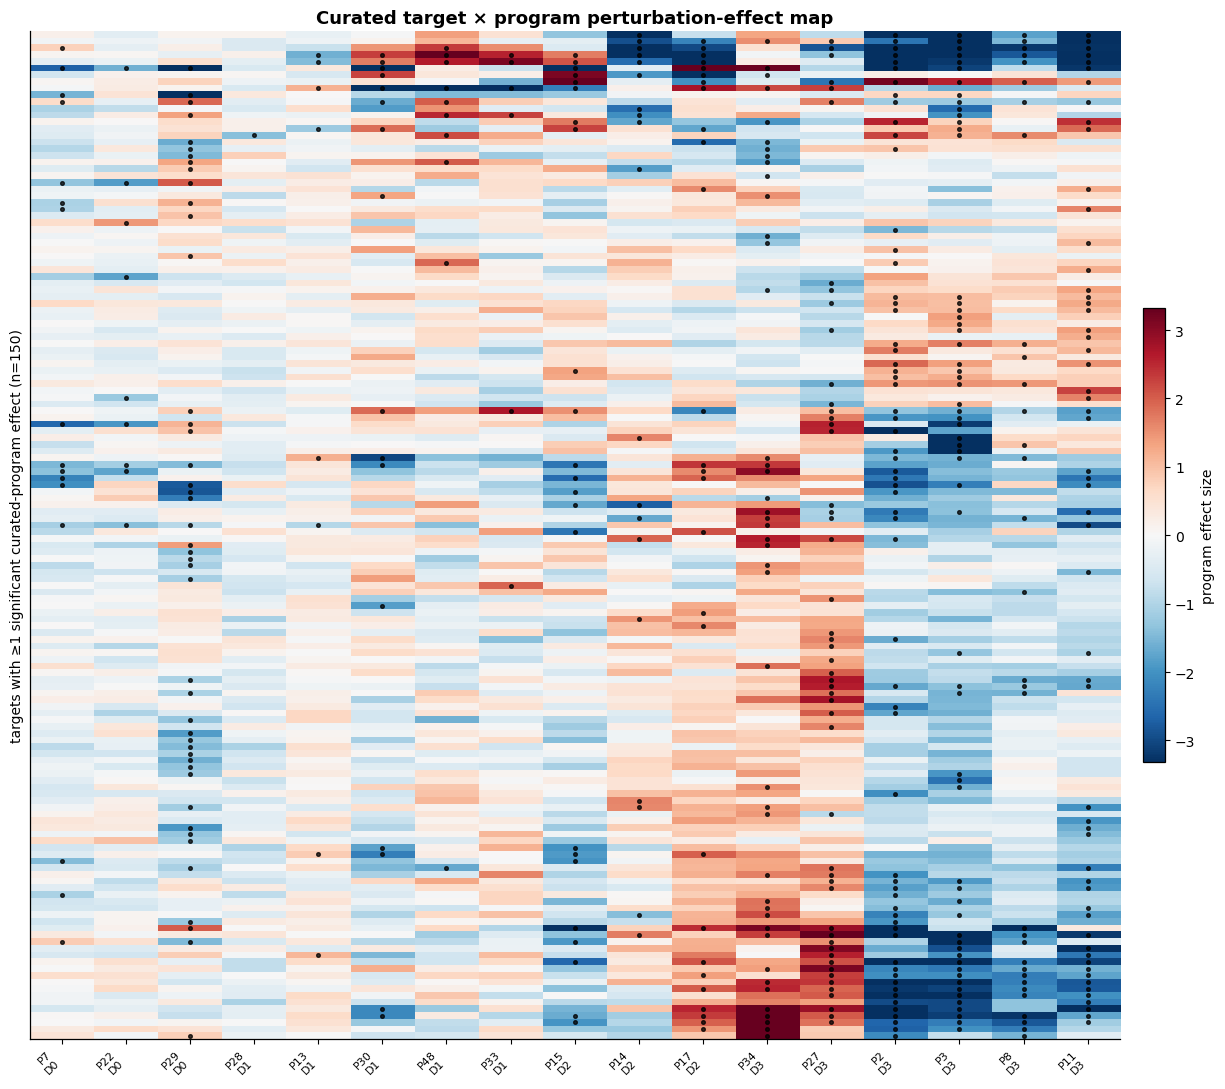

In [5]:
def plot_curated_effect_heatmap(effect_mat, fdr_mat, stem='curated_target_program_heatmap', max_targets=150):
    # select targets with at least one significant effect and then strongest effects
    sig_any = (fdr_mat < FDR_CUTOFF).any(axis=1)
    mat = effect_mat.loc[sig_any].copy()
    if len(mat) == 0:
        print('No significant target-program effects found at FDR cutoff; plotting strongest targets instead.')
        mat = effect_mat.copy()
    # rank by max abs effect and limit for readability
    rank = mat.abs().max(axis=1).sort_values(ascending=False)
    mat = mat.loc[rank.index[:max_targets]]
    fdr_sub = fdr_mat.loc[mat.index, mat.columns]

    # cluster rows only
    mfill = mat.fillna(0)
    if len(mfill) > 2:
        row_order = leaves_list(linkage(pdist(mfill.values, metric='euclidean'), method='average'))
        mat = mat.iloc[row_order]
        fdr_sub = fdr_sub.iloc[row_order]

    vmax = np.nanquantile(np.abs(mat.values), 0.98)
    vmax = max(vmax, 0.25)

    fig, ax = plt.subplots(figsize=(max(8, 0.55*mat.shape[1]+3), max(5, 0.06*mat.shape[0]+2)))
    im = ax.imshow(mat.values, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax)

    # significance dots
    yy, xx = np.where((fdr_sub.values < FDR_CUTOFF) & ~np.isnan(fdr_sub.values))
    ax.scatter(xx, yy, s=7, c='black', alpha=0.75)

    ax.set_xticks(range(mat.shape[1]))
    xticklabels = []
    for p in mat.columns:
        pid = int(p.replace('P',''))
        xticklabels.append(f'{p}\n{program_to_day.get(pid, "")}')
    ax.set_xticklabels(xticklabels, rotation=45, ha='right', fontsize=8)
    ax.set_yticks([])
    ax.set_title('Curated target × program perturbation-effect map', fontsize=13, weight='bold')
    ax.set_ylabel(f'targets with ≥1 significant curated-program effect (n={mat.shape[0]})')

    cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
    cbar.set_label('program effect size')
    fig.tight_layout()
    savefig(fig, stem)
    plt.show()
    return mat

heatmap_targets = plot_curated_effect_heatmap(effect_mat, fdr_mat)

## 3. Program-defined target fingerprints using raw effects

This is designed to avoid ad hoc subtraction. Each selected target is shown as its **raw effect profile** across expert-curated programs ordered by timepoint.

saved: outputs_program_first_advanced/selected_target_raw_program_fingerprints_heatmap.png
saved: outputs_program_first_advanced/selected_target_raw_program_fingerprints_heatmap.pdf
saved: outputs_program_first_advanced/selected_target_raw_program_fingerprints_heatmap.svg


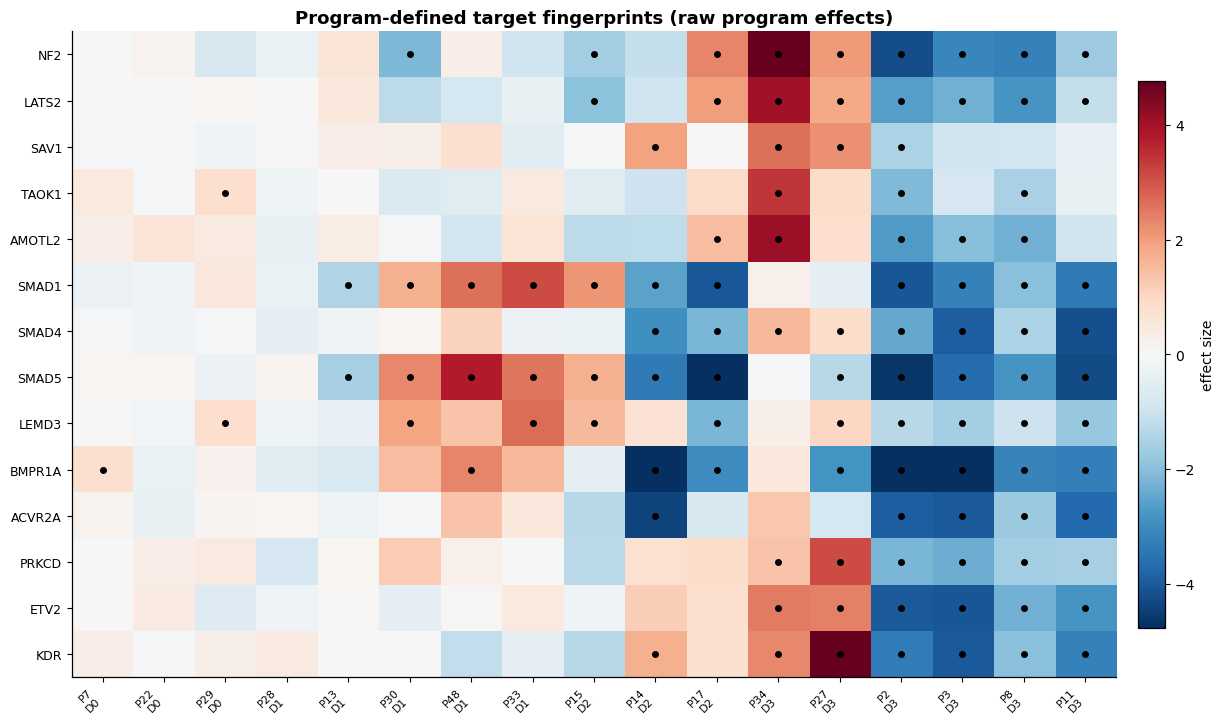

saved: outputs_program_first_advanced/target_fingerprint_NF2.png
saved: outputs_program_first_advanced/target_fingerprint_NF2.pdf
saved: outputs_program_first_advanced/target_fingerprint_NF2.svg
saved: outputs_program_first_advanced/target_fingerprint_LATS2.png
saved: outputs_program_first_advanced/target_fingerprint_LATS2.pdf
saved: outputs_program_first_advanced/target_fingerprint_LATS2.svg
saved: outputs_program_first_advanced/target_fingerprint_SAV1.png
saved: outputs_program_first_advanced/target_fingerprint_SAV1.pdf
saved: outputs_program_first_advanced/target_fingerprint_SAV1.svg
saved: outputs_program_first_advanced/target_fingerprint_TAOK1.png
saved: outputs_program_first_advanced/target_fingerprint_TAOK1.pdf
saved: outputs_program_first_advanced/target_fingerprint_TAOK1.svg
saved: outputs_program_first_advanced/target_fingerprint_AMOTL2.png
saved: outputs_program_first_advanced/target_fingerprint_AMOTL2.pdf
saved: outputs_program_first_advanced/target_fingerprint_AMOTL2.svg
s

In [6]:
# Program-defined target fingerprints.
# This uses raw effect values per program, not program differences.

def get_target_set_labels(targets):
    labels = {}
    for set_name, genes in TARGET_SETS_BUILTIN.items():
        for g in genes:
            labels.setdefault(g, []).append(set_name)
    return {t: ';'.join(labels.get(t, [])) for t in targets}

selected_targets = [t for t in SELECTED_TARGETS_FOR_CARDS if t in effect_mat.index]
# add top strongest targets if few selected are present
if len(selected_targets) < 10:
    top = effect_mat.abs().max(axis=1).sort_values(ascending=False).head(20).index.tolist()
    selected_targets = list(dict.fromkeys(selected_targets + top))

fp = effect_mat.loc[selected_targets, program_order].copy()
fp_fdr = fdr_mat.loc[selected_targets, program_order].copy()
fp.to_csv(OUTDIR / 'selected_target_raw_program_fingerprints.csv')

vmax = np.nanquantile(np.abs(fp.values), 0.98)
vmax = max(vmax, 0.25)
fig, ax = plt.subplots(figsize=(max(9, 0.55*fp.shape[1]+3), max(4, 0.42*fp.shape[0]+1.5)))
im = ax.imshow(fp.values, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
# significance dots
ys, xs = np.where(fp_fdr.values < FDR_CUTOFF)
ax.scatter(xs, ys, c='black', s=16)
ax.set_xticks(range(fp.shape[1]))
ax.set_xticklabels([f'{p}\n{program_to_day[int(p.replace("P", ""))]}' for p in fp.columns], rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(fp.shape[0]))
ax.set_yticklabels(fp.index, fontsize=9)
ax.set_title('Program-defined target fingerprints (raw program effects)', fontsize=13, weight='bold')
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label('effect size')
fig.tight_layout()
savefig(fig, 'selected_target_raw_program_fingerprints_heatmap')
plt.show()

# Line-style fingerprints: useful for selected examples.
for target in selected_targets[:12]:
    y = effect_mat.loc[target, program_order]
    fig, ax = plt.subplots(figsize=(7.8, 2.5))
    x = np.arange(len(program_order))
    colors = ['#999999' if pd.isna(v) else ('#d95f02' if v > 0 else '#1f78b4') for v in y]
    ax.axhline(0, color='#999999', lw=0.8, ls='--')
    ax.plot(x, y.values, color='#333333', lw=1.0, alpha=0.8)
    ax.scatter(x, y.values, c=colors, s=42, zorder=3)
    # mark significant
    sig = fdr_mat.loc[target, program_order] < FDR_CUTOFF
    ax.scatter(x[sig.values], y.values[sig.values], facecolors='none', edgecolors='black', s=90, lw=1.0, zorder=4)
    ax.set_xticks(x)
    ax.set_xticklabels(program_order, rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('effect')
    ax.set_title(f'{target}: raw program-effect fingerprint', fontsize=11, weight='bold')
    fig.tight_layout()
    savefig(fig, f'target_fingerprint_{target}')
    plt.close(fig)

## 4. Lagged program-coupling network

Edges are correlations of target-level effects between programs. The graph is plotted left-to-right by annotated day. This is a distilled view of program-effect coupling across time.

,program1,program2,program1_day,program2_day,program1_name,program2_name,n_targets,pearson_r,p_value,abs_r,day_distance,fdr
130,P2,P3,D3,D3,Artery endothelium 1,Endothelial function 1,299,0.788354,1.288526e-64,0.788354,0,1.752396e-62
132,P2,P11,D3,D3,Artery endothelium 1,Endothelial function 2,299,0.773086,1.142161e-60,0.773086,0,7.766695e-59
131,P2,P8,D3,D3,Artery endothelium 1,Artery endothelium 2,299,0.755801,1.480051e-56,0.755801,0,6.709563e-55
134,P3,P11,D3,D3,Endothelial function 1,Endothelial function 2,299,0.675885,2.969559e-41,0.675885,0,1.009650e-39
122,P34,P2,D3,D3,"Mesenchyme, YAP/TAZ-induced",Artery endothelium 1,299,-0.644869,1.520131e-36,0.644869,0,4.134757e-35
101,P15,P17,D2,D2,Vascular progenitor,"Lateral mesoderm, YAP/TAZ-induced",299,-0.633681,5.619035e-35,0.633681,0,1.273648e-33
133,P3,P8,D3,D3,Endothelial function 1,Artery endothelium 2,299,0.624873,8.696247e-34,0.624873,0,1.689557e-32
135,P8,P11,D3,D3,Artery endothelium 2,Endothelial function 2,299,0.617689,7.620025e-33,0.617689,0,1.295404e-31
74,P30,P17,D1,D2,"Primitive streak, BMP-repressed 1","Lateral mesoderm, YAP/TAZ-induced",299,-0.595654,4.234971e-30,0.595654,1,6.399511e-29
124,P34,P8,D3,D3,"Mesenchyme, YAP/TAZ-induced",Artery endothelium 2,299,-0.582363,1.523250e-28,0.582363,0,2.071620e-27


saved: outputs_program_first_advanced/curated_program_effect_correlation_heatmap.png
saved: outputs_program_first_advanced/curated_program_effect_correlation_heatmap.pdf
saved: outputs_program_first_advanced/curated_program_effect_correlation_heatmap.svg


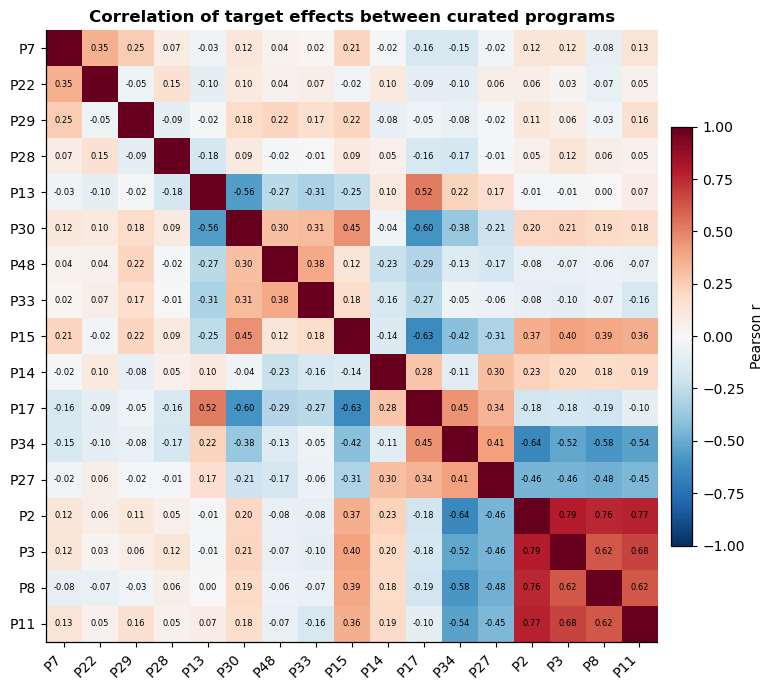

In [7]:
# Compute pairwise correlations among curated programs across targets.
records = []
for p1, p2 in itertools.combinations(program_order, 2):
    sub = effect_mat[[p1, p2]].dropna()
    if len(sub) < MIN_OVERLAP_TARGETS_FOR_CORR:
        continue
    r, p = stats.pearsonr(sub[p1], sub[p2])
    pid1, pid2 = int(p1.replace('P','')), int(p2.replace('P',''))
    records.append({
        'program1': p1, 'program2': p2,
        'program1_day': program_to_day[pid1], 'program2_day': program_to_day[pid2],
        'program1_name': program_to_name[pid1], 'program2_name': program_to_name[pid2],
        'n_targets': len(sub), 'pearson_r': r, 'p_value': p,
        'abs_r': abs(r),
        'day_distance': int(program_to_day[pid2][1:]) - int(program_to_day[pid1][1:])
    })
prog_corr = pd.DataFrame(records)
prog_corr['fdr'] = bh_fdr(prog_corr['p_value'])
prog_corr.to_csv(OUTDIR / 'curated_program_pairwise_effect_correlations.csv', index=False)
display(prog_corr.sort_values('abs_r', ascending=False).head(20))

# Plot full correlation heatmap
corr_mat = effect_mat[program_order].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr_mat.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(program_order)))
ax.set_yticks(range(len(program_order)))
ax.set_xticklabels(program_order, rotation=45, ha='right')
ax.set_yticklabels(program_order)
for i in range(len(program_order)):
    for j in range(len(program_order)):
        if i != j:
            ax.text(j, i, f'{corr_mat.iloc[i,j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title('Correlation of target effects between curated programs', fontsize=12, weight='bold')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label='Pearson r')
fig.tight_layout()
savefig(fig, 'curated_program_effect_correlation_heatmap')
plt.show()

saved: outputs_program_first_advanced/lagged_program_coupling_network.png
saved: outputs_program_first_advanced/lagged_program_coupling_network.pdf
saved: outputs_program_first_advanced/lagged_program_coupling_network.svg


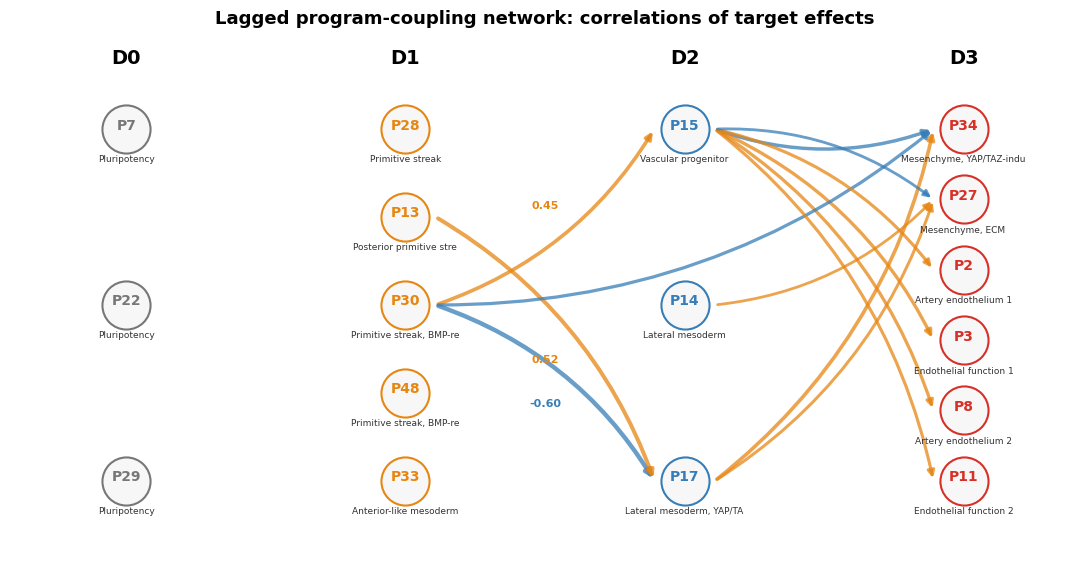

In [8]:
# Draw lagged network only among different days, with edges above threshold.
day_x = {'D0':0, 'D1':1.2, 'D2':2.4, 'D3':3.6}
# assign y positions within each day
pos = {}
for day, sub_ann in ann.groupby('day', sort=False):
    programs = sub_ann.sort_values('program_order')['program_label'].tolist()
    ys = np.linspace(1, -1, len(programs)) if len(programs) > 1 else [0]
    for p, y in zip(programs, ys):
        pos[p] = (day_x[day], y)

edges_to_plot = prog_corr[(prog_corr['day_distance'] > 0) & (prog_corr['abs_r'] >= MIN_ABS_R_FOR_NETWORK)].copy()
edges_to_plot = edges_to_plot.sort_values('abs_r', ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.8))
# nodes
for _, row in ann.iterrows():
    p = row['program_label']
    x, y = pos[p]
    group = row['program_group']
    face = '#f7f7f7'
    edge = {'D0':'#777777','D1':'#E68613','D2':'#377EB8','D3':'#D73027'}.get(row['day'], '#333333')
    ax.scatter([x], [y], s=1200, facecolor=face, edgecolor=edge, linewidth=1.5, zorder=4)
    ax.text(x, y+0.02, p, ha='center', va='center', fontsize=10, weight='bold', color=edge, zorder=5)
    ax.text(x, y-0.15, str(row['expert_annotation'])[:24], ha='center', va='top', fontsize=6.5, color='#333333', zorder=5)

# day labels
for d, x in day_x.items():
    ax.text(x, 1.35, d, ha='center', va='bottom', fontsize=14, weight='bold')

# edges
for _, e in edges_to_plot.iterrows():
    p1, p2, r = e['program1'], e['program2'], e['pearson_r']
    x1, y1 = pos[p1]
    x2, y2 = pos[p2]
    color = '#E68613' if r > 0 else '#377EB8'
    lw = 0.8 + 4.0 * min(abs(r), 1)
    rad = 0.18 if y2 >= y1 else -0.18
    arrow = FancyArrowPatch((x1+0.13, y1), (x2-0.13, y2),
                            connectionstyle=f'arc3,rad={rad}',
                            arrowstyle='-|>', mutation_scale=10,
                            lw=lw, color=color, alpha=0.75, zorder=2)
    ax.add_patch(arrow)
    if abs(r) >= 0.45:
        ax.text((x1+x2)/2, (y1+y2)/2 + rad*0.35, f'{r:.2f}', color=color,
                fontsize=8, ha='center', va='center', weight='bold')

ax.set_xlim(-0.5, 4.1)
ax.set_ylim(-1.45, 1.55)
ax.axis('off')
ax.set_title('Lagged program-coupling network: correlations of target effects', fontsize=13, weight='bold')
fig.tight_layout()
savefig(fig, 'lagged_program_coupling_network')
plt.show()

## 5. D2-to-D3 prediction / mediation-style analyses without ad hoc subtraction

This section asks whether raw D2 program effects explain raw D3 endpoint-program effects. It does **not** define P17−P15 or P34−EC scores. Instead, it fits regressions such as `P34 effect ~ P15 + P14 + P17` and visualizes pairwise raw-effect relationships.

,D2_program,D3_program,n_targets,pearson_r,p_value,fdr
0,P15,P34,299,-0.421376,2.674219e-14,2.406797e-13
1,P15,P27,299,-0.310553,4.166265e-08,9.374097e-08
16,P17,P8,299,-0.194842,7.052002e-04,1.013992e-03
14,P17,P2,299,-0.183433,1.444319e-03,1.856981e-03
15,P17,P3,299,-0.176985,2.127553e-03,2.393497e-03
6,P14,P34,299,-0.107089,6.441456e-02,6.820366e-02
17,P17,P11,299,-0.100286,8.341443e-02,8.341443e-02
10,P14,P8,299,0.180349,1.741045e-03,2.089254e-03
11,P14,P11,299,0.194257,7.323274e-04,1.013992e-03
9,P14,P3,299,0.196216,6.450975e-04,1.013992e-03


saved: outputs_program_first_advanced/D2_to_D3_raw_effect_correlation_matrix.png
saved: outputs_program_first_advanced/D2_to_D3_raw_effect_correlation_matrix.pdf
saved: outputs_program_first_advanced/D2_to_D3_raw_effect_correlation_matrix.svg


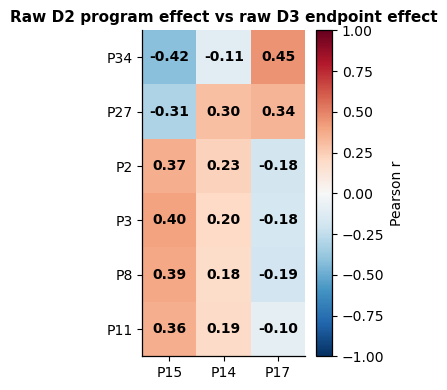

In [9]:
D2_PROGRAMS = [p for p in ['P15','P14','P17'] if p in effect_mat.columns]
D3_PROGRAMS = [p for p in ['P34','P27','P2','P3','P8','P11'] if p in effect_mat.columns]

# Pairwise D2->D3 correlations
pair_records = []
for d2 in D2_PROGRAMS:
    for d3 in D3_PROGRAMS:
        sub = effect_mat[[d2, d3]].dropna()
        if len(sub) < MIN_OVERLAP_TARGETS_FOR_CORR:
            continue
        r, p = stats.pearsonr(sub[d2], sub[d3])
        pair_records.append({'D2_program': d2, 'D3_program': d3, 'n_targets': len(sub), 'pearson_r': r, 'p_value': p})
pair_df = pd.DataFrame(pair_records)
pair_df['fdr'] = bh_fdr(pair_df['p_value'])
pair_df.to_csv(OUTDIR / 'D2_to_D3_raw_program_effect_correlations.csv', index=False)
display(pair_df.sort_values('pearson_r'))

# Plot D2->D3 correlation matrix
pair_mat = pair_df.pivot(index='D3_program', columns='D2_program', values='pearson_r').reindex(index=D3_PROGRAMS, columns=D2_PROGRAMS)
fig, ax = plt.subplots(figsize=(4.5, 4.0))
im = ax.imshow(pair_mat.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(D2_PROGRAMS)))
ax.set_xticklabels(D2_PROGRAMS, fontsize=10)
ax.set_yticks(range(len(D3_PROGRAMS)))
ax.set_yticklabels(D3_PROGRAMS, fontsize=10)
for i in range(pair_mat.shape[0]):
    for j in range(pair_mat.shape[1]):
        val = pair_mat.iloc[i,j]
        if pd.notna(val):
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=10, weight='bold')
ax.set_title('Raw D2 program effect vs raw D3 endpoint effect', fontsize=11, weight='bold')
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03, label='Pearson r')
fig.tight_layout()
savefig(fig, 'D2_to_D3_raw_effect_correlation_matrix')
plt.show()

,n,r2,adj_r2,intercept,beta_P15,beta_P14,beta_P17,D3_program
0,299,0.287915,0.280674,-1.926176e-17,-0.213129,-0.244401,0.382745,P34
1,299,0.179186,0.170839,3.210293e-17,-0.173679,0.230044,0.165063,P27
2,299,0.214810,0.206825,-7.704703e-17,0.398544,0.289923,-0.012243,P2
3,299,0.225536,0.217660,5.136468e-17,0.464128,0.247999,0.047529,P3
4,299,0.204302,0.196210,-2.568234e-17,0.422153,0.237925,0.005900,P8
5,299,0.205166,0.197083,6.420586e-18,0.486739,0.221589,0.145968,P11


saved: outputs_program_first_advanced/D2_to_D3_multivariable_prediction_summary.png
saved: outputs_program_first_advanced/D2_to_D3_multivariable_prediction_summary.pdf
saved: outputs_program_first_advanced/D2_to_D3_multivariable_prediction_summary.svg


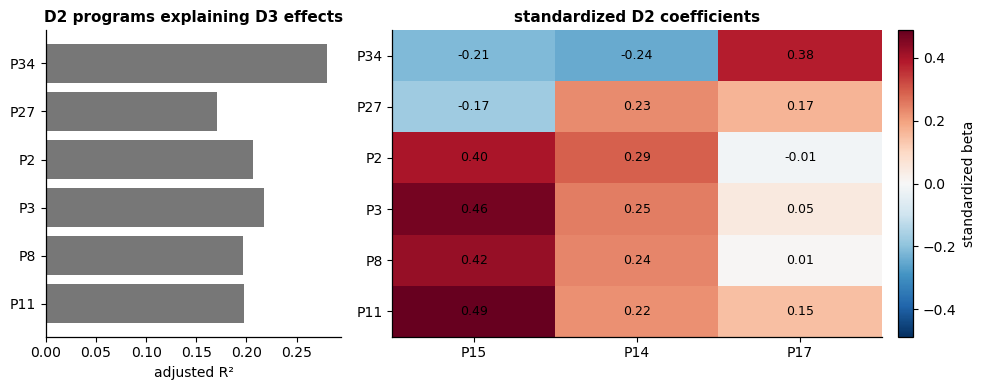

In [10]:
# Multivariable prediction: each D3 program effect ~ P15 + P14 + P17 effects.
# This provides an R² / standardized coefficient view without defining differences.

def fit_linear_model(X, y):
    # z-score predictors and outcome for comparable coefficients
    X = pd.DataFrame(X).astype(float)
    y = pd.Series(y).astype(float)
    dat = pd.concat([X, y.rename('y')], axis=1).dropna()
    if len(dat) < 10:
        return None
    Xz = dat[X.columns].apply(zscore_series)
    yz = zscore_series(dat['y'])
    Xdesign = np.column_stack([np.ones(len(Xz)), Xz.values])
    beta, *_ = np.linalg.lstsq(Xdesign, yz.values, rcond=None)
    yhat = Xdesign @ beta
    ss_res = np.sum((yz.values - yhat)**2)
    ss_tot = np.sum((yz.values - yz.mean())**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
    adj_r2 = 1 - (1-r2)*(len(dat)-1)/(len(dat)-Xz.shape[1]-1) if len(dat) > Xz.shape[1]+1 else np.nan
    return {'n': len(dat), 'r2': r2, 'adj_r2': adj_r2, 'intercept': beta[0], **{f'beta_{c}': beta[i+1] for i,c in enumerate(X.columns)}}

model_rows = []
for d3 in D3_PROGRAMS:
    res = fit_linear_model(effect_mat[D2_PROGRAMS], effect_mat[d3])
    if res:
        res['D3_program'] = d3
        model_rows.append(res)
model_df = pd.DataFrame(model_rows)
model_df.to_csv(OUTDIR / 'D3_programs_predicted_by_D2_programs_multivariable_regression.csv', index=False)
display(model_df)

# plot adjusted R² and standardized coefficients
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), gridspec_kw={'width_ratios':[1, 1.8]})
axes[0].barh(model_df['D3_program'], model_df['adj_r2'], color='#777777')
axes[0].set_xlabel('adjusted R²')
axes[0].set_title('D2 programs explaining D3 effects', fontsize=11, weight='bold')
axes[0].invert_yaxis()

coef_cols = [f'beta_{p}' for p in D2_PROGRAMS]
coef_mat = model_df.set_index('D3_program')[coef_cols]
vmax = np.nanmax(np.abs(coef_mat.values))
vmax = max(vmax, 0.1)
im = axes[1].imshow(coef_mat.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[1].set_xticks(range(len(coef_cols)))
axes[1].set_xticklabels([c.replace('beta_','') for c in coef_cols])
axes[1].set_yticks(range(len(coef_mat.index)))
axes[1].set_yticklabels(coef_mat.index)
for i in range(coef_mat.shape[0]):
    for j in range(coef_mat.shape[1]):
        axes[1].text(j, i, f'{coef_mat.iloc[i,j]:.2f}', ha='center', va='center', fontsize=9)
axes[1].set_title('standardized D2 coefficients', fontsize=11, weight='bold')
fig.colorbar(im, ax=axes[1], fraction=0.05, pad=0.03, label='standardized beta')
fig.tight_layout()
savefig(fig, 'D2_to_D3_multivariable_prediction_summary')
plt.show()

saved: outputs_program_first_advanced/selected_raw_program_effect_scatterplots.png
saved: outputs_program_first_advanced/selected_raw_program_effect_scatterplots.pdf
saved: outputs_program_first_advanced/selected_raw_program_effect_scatterplots.svg


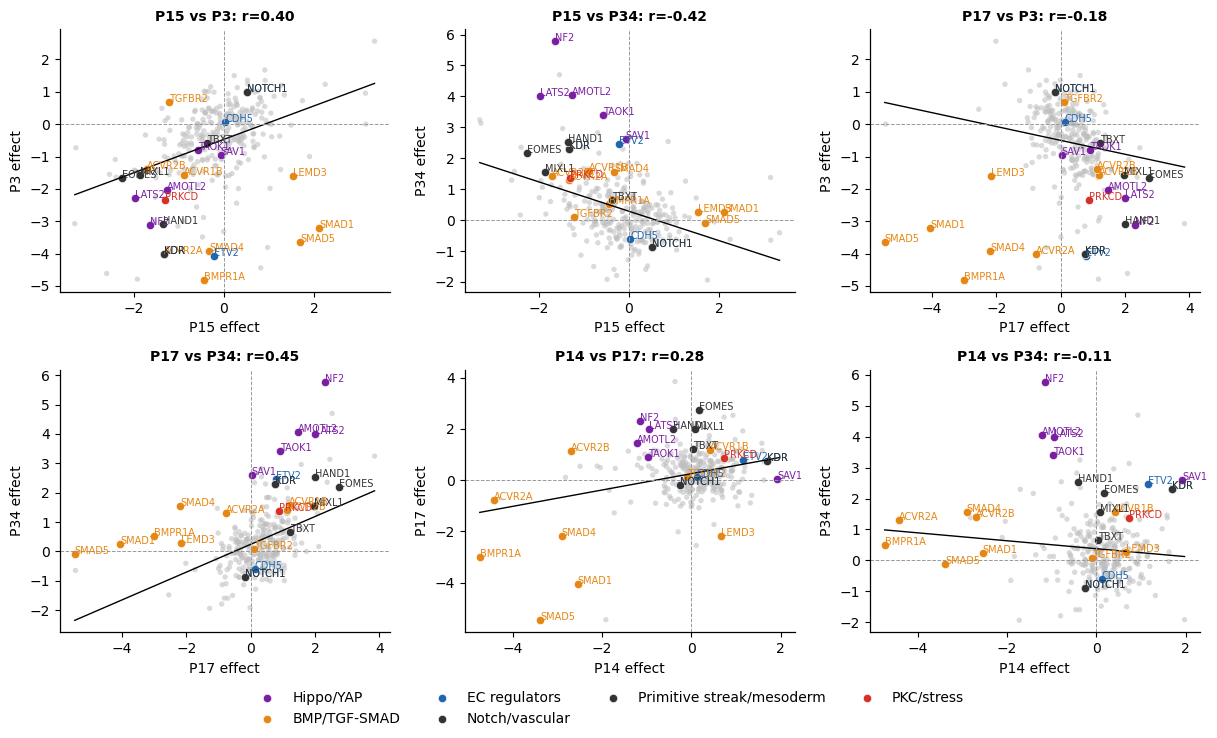

In [11]:
# Pairwise scatter plots for selected D2/D3 program pairs.
SCATTER_PAIRS = [('P15','P3'), ('P15','P34'), ('P17','P3'), ('P17','P34'), ('P14','P17'), ('P14','P34')]
SCATTER_PAIRS = [(a,b) for a,b in SCATTER_PAIRS if a in effect_mat.columns and b in effect_mat.columns]

ncols = 3
nrows = math.ceil(len(SCATTER_PAIRS)/ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.1*ncols, 3.7*nrows), squeeze=False)
for ax, (a,b) in zip(axes.ravel(), SCATTER_PAIRS):
    sub = effect_mat[[a,b]].dropna()
    x, y = sub[a], sub[b]
    r, p = stats.pearsonr(x, y)
    ax.scatter(x, y, s=15, c='#BDBDBD', alpha=0.55, edgecolors='none')
    # selected target labels/colors
    for set_name, genes in TARGET_SETS_BUILTIN.items():
        hits = [g for g in genes if g in sub.index]
        if not hits:
            continue
        color = {'Hippo/YAP':'#7A1FA2','BMP/TGF-SMAD':'#E68613','EC regulators':'#2166AC','PKC/stress':'#D73027'}.get(set_name, '#333333')
        ax.scatter(x.loc[hits], y.loc[hits], s=35, c=color, label=set_name, edgecolors='white', linewidth=0.4)
        for g in hits:
            ax.text(x.loc[g], y.loc[g], g, fontsize=7, color=color)
    coef = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, coef[0]*xx + coef[1], color='black', lw=1)
    ax.axhline(0, color='#999999', ls='--', lw=0.7)
    ax.axvline(0, color='#999999', ls='--', lw=0.7)
    ax.set_xlabel(f'{a} effect')
    ax.set_ylabel(f'{b} effect')
    ax.set_title(f'{a} vs {b}: r={r:.2f}', fontsize=10, weight='bold')
for ax in axes.ravel()[len(SCATTER_PAIRS):]:
    ax.axis('off')
handles, labels = axes[0,0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False)
fig.tight_layout(rect=[0,0.06,1,1])
savefig(fig, 'selected_raw_program_effect_scatterplots')
plt.show()

## 6. Program-defined bottleneck proxy plots

These plots avoid subtracting program effects. They ask whether a perturbation's raw effect on the P15 vascular progenitor program is associated with raw effects on D3 EC or D3 alternative programs. Quadrants are descriptive only.

saved: outputs_program_first_advanced/program_defined_bottleneck_proxy_scatterplots.png
saved: outputs_program_first_advanced/program_defined_bottleneck_proxy_scatterplots.pdf
saved: outputs_program_first_advanced/program_defined_bottleneck_proxy_scatterplots.svg


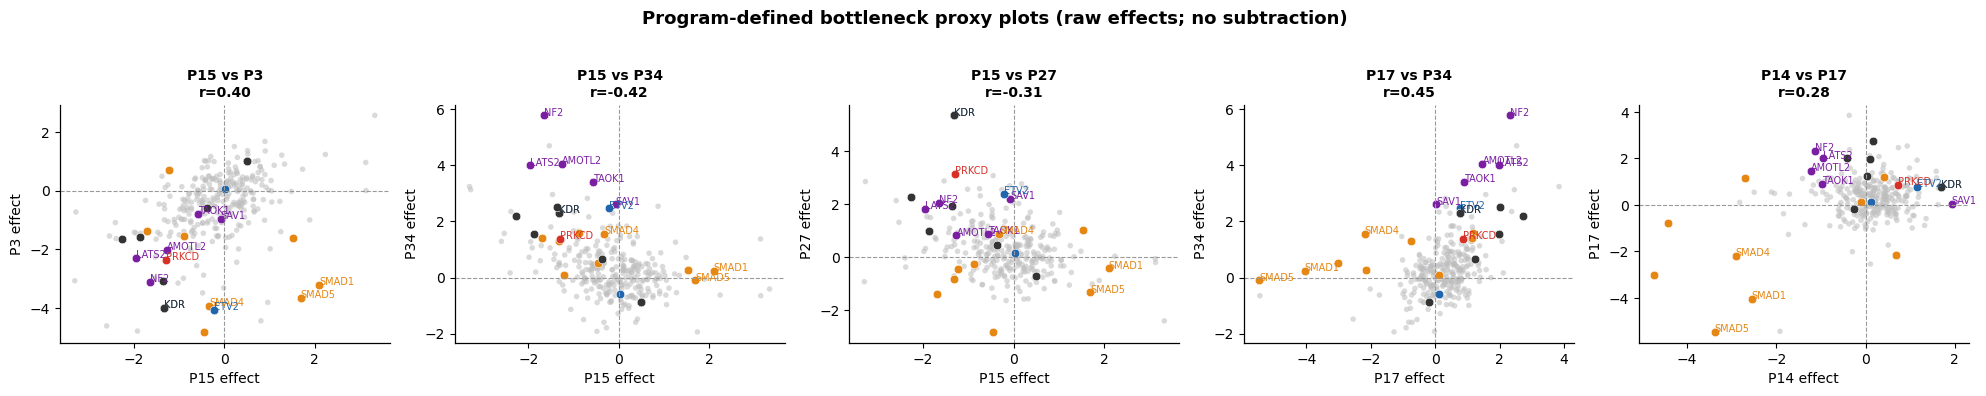

In [12]:
BOTTLENECK_PAIRS = [('P15','P3'), ('P15','P34'), ('P15','P27'), ('P17','P34'), ('P14','P17')]
BOTTLENECK_PAIRS = [(a,b) for a,b in BOTTLENECK_PAIRS if a in effect_mat.columns and b in effect_mat.columns]

fig, axes = plt.subplots(1, len(BOTTLENECK_PAIRS), figsize=(4.0*len(BOTTLENECK_PAIRS), 3.8), squeeze=False)
for ax, (a,b) in zip(axes.ravel(), BOTTLENECK_PAIRS):
    sub = effect_mat[[a,b]].dropna()
    ax.scatter(sub[a], sub[b], s=16, c='#BDBDBD', alpha=0.55, edgecolors='none')
    # highlight built-in target groups
    for set_name, genes in TARGET_SETS_BUILTIN.items():
        hits = [g for g in genes if g in sub.index]
        if not hits: continue
        color = {'Hippo/YAP':'#7A1FA2','BMP/TGF-SMAD':'#E68613','EC regulators':'#2166AC','PKC/stress':'#D73027'}.get(set_name, '#333333')
        ax.scatter(sub.loc[hits, a], sub.loc[hits, b], s=38, c=color, edgecolors='white', linewidth=0.4)
        for g in hits:
            if g in ['NF2','LATS2','SAV1','TAOK1','AMOTL2','PRKCD','SMAD1','SMAD4','SMAD5','KDR','ETV2']:
                ax.text(sub.loc[g,a], sub.loc[g,b], g, fontsize=7, color=color)
    ax.axhline(0, color='#999999', ls='--', lw=0.8)
    ax.axvline(0, color='#999999', ls='--', lw=0.8)
    r, p = stats.pearsonr(sub[a], sub[b])
    ax.set_title(f'{a} vs {b}\nr={r:.2f}', fontsize=10, weight='bold')
    ax.set_xlabel(f'{a} effect')
    ax.set_ylabel(f'{b} effect')
fig.suptitle('Program-defined bottleneck proxy plots (raw effects; no subtraction)', fontsize=13, weight='bold', y=1.03)
fig.tight_layout()
savefig(fig, 'program_defined_bottleneck_proxy_scatterplots')
plt.show()

## 7. Program-level regulon / signature overlay

This section annotates programs using overlaps between program loading genes and biological signatures. It is a program-level annotation analysis, not a cluster analysis.

If you have a custom signature file, set `CUSTOM_SIGNATURES_CSV` above. It should have columns `signature` and `gene`.

saved: outputs_program_first_advanced/program_signature_enrichment_heatmap.png
saved: outputs_program_first_advanced/program_signature_enrichment_heatmap.pdf
saved: outputs_program_first_advanced/program_signature_enrichment_heatmap.svg


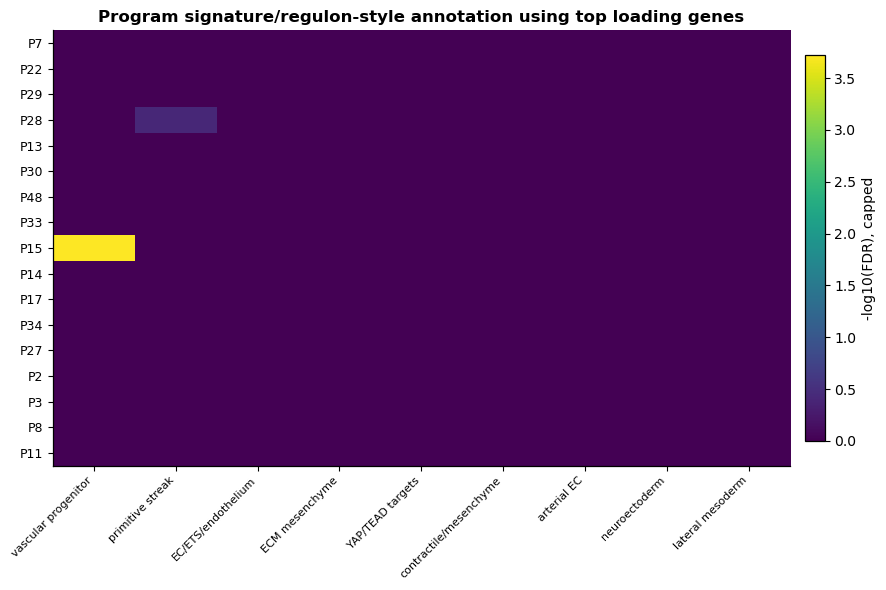

,program_id,program_label,signature,n_program_genes,n_signature_genes,overlap_n,p_value,overlap_genes,fdr,neglog10_fdr,program_order,expert_annotation,day,program_group
65,15,P15,vascular progenitor,10,7,5,0.000001,APLNR;FLI1;KDR;NRP2;TAL1,0.000190,3.721772,8,Vascular progenitor,D2,Vascular progenitor / pre-EC
106,28,P28,primitive streak,10,9,3,0.004968,MIXL1;SP5;TBXT,0.380022,0.420192,3,Primitive streak,D1,Primitive streak / early mesoderm
0,2,P2,EC/ETS/endothelium,10,13,1,0.463306,FLT1,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
1,2,P2,arterial EC,10,8,1,0.315020,NRP1,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
4,2,P2,YAP/TEAD targets,10,10,0,1.000000,,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
5,2,P2,contractile/mesenchyme,10,10,0,1.000000,,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
2,2,P2,vascular progenitor,10,7,0,1.000000,,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
3,2,P2,lateral mesoderm,10,8,0,1.000000,,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
8,2,P2,neuroectoderm,10,9,0,1.000000,,1.000000,-0.000000,13,Artery endothelium 1,D3,Endothelial endpoint
9,3,P3,EC/ETS/endothelium,10,13,0,1.000000,,1.000000,-0.000000,14,Endothelial function 1,D3,Endothelial endpoint


In [13]:
# Built-in signatures for quick program annotation. Edit or replace with curated external signatures.
SIGNATURES_BUILTIN = {
    'EC/ETS/endothelium': ['PECAM1','CDH5','VWF','ERG','FLI1','ETS1','SOX17','KDR','FLT1','ESAM','CLDN5','RAMP2','EMCN'],
    'arterial EC': ['SOX17','EFNB2','DLL4','NOTCH1','UNC5B','GJA5','CXCR4','NRP1'],
    'vascular progenitor': ['TAL1','FLI1','KDR','APLNR','NRP2','SOX7','SOX17'],
    'lateral mesoderm': ['HAND1','HAND2','FOXF1','TBX4','ALDH1A2','PRRX1','PRRX2','ISL1'],
    'YAP/TEAD targets': ['CCN2','CTGF','CCN1','CYR61','ANKRD1','AMOTL2','SERPINE1','THBS1','AREG','MYL9'],
    'contractile/mesenchyme': ['ACTA2','TAGLN','MYL9','CNN1','CALD1','COL1A1','COL3A1','FN1','PRRX1','PDGFRA'],
    'ECM mesenchyme': ['COL1A1','COL1A2','COL3A1','COL5A1','COL6A1','FN1','DCN','LUM','FBN1','POSTN'],
    'primitive streak': ['TBXT','MIXL1','EOMES','MESP1','SP5','WNT3A','NODAL','LEFTY1','LEFTY2'],
    'neuroectoderm': ['SOX2','PAX6','OTX2','ZIC1','ZIC2','ZIC3','NES','SOX1','WLS'],
}

# Load custom signatures if supplied.
if CUSTOM_SIGNATURES_CSV is not None and Path(CUSTOM_SIGNATURES_CSV).exists():
    sig_df = pd.read_csv(CUSTOM_SIGNATURES_CSV)
    sig_col = pick_col(sig_df, ['signature','set','geneset','term'], label='signature column')
    gene_col = pick_col(sig_df, ['gene','symbol','gene_symbol'], label='gene column')
    custom = sig_df.groupby(sig_col)[gene_col].apply(lambda x: sorted(set(map(lambda g: str(g).upper(), x)))).to_dict()
    SIGNATURES = {**SIGNATURES_BUILTIN, **custom}
else:
    SIGNATURES = SIGNATURES_BUILTIN

# Load top loaded genes from Summary sheet if available; otherwise use representative genes from annotation.
program_gene_lists = {}
try:
    summary = pd.read_excel(CNMF_XLSX, sheet_name=SUMMARY_SHEET)
    prog_col_sum = pick_col(summary, ['program_name','program_id','program'], label='summary program column')
    top_col_sum = pick_col(summary, ['top10_loaded_genes','top_loaded_genes','loaded_genes','top_genes'], required=False, label='top genes column')
    if top_col_sum is not None:
        tmp = summary.copy()
        tmp['program_id'] = tmp[prog_col_sum].map(extract_program_id).astype('Int64')
        for _, row in tmp[tmp['program_id'].isin(curated_programs)].iterrows():
            program_gene_lists[int(row['program_id'])] = parse_gene_list(row[top_col_sum])
except Exception as e:
    print('Could not load Summary top genes; using representative genes from annotation.', e)

for _, row in ann.iterrows():
    pid = int(row['program_id'])
    if pid not in program_gene_lists or len(program_gene_lists[pid]) == 0:
        program_gene_lists[pid] = parse_gene_list(row['representative_genes'])

# Universe = all genes occurring in signatures + program lists
universe = set()
for genes in SIGNATURES.values(): universe.update([g.upper() for g in genes])
for genes in program_gene_lists.values(): universe.update([g.upper() for g in genes])
N = max(len(universe), 1)

rows = []
for pid, genes in program_gene_lists.items():
    genes = sorted(set([g.upper() for g in genes]))
    n = len(genes)
    for sig, sig_genes in SIGNATURES.items():
        sig_genes = sorted(set([g.upper() for g in sig_genes]))
        K = len(sig_genes)
        overlap = sorted(set(genes) & set(sig_genes))
        k = len(overlap)
        p = fisher_overlap(k, K, n, N)
        rows.append({'program_id':pid, 'program_label':f'P{pid}', 'signature':sig, 'n_program_genes':n, 'n_signature_genes':K, 'overlap_n':k, 'p_value':p, 'overlap_genes':';'.join(overlap)})
sig_enrich = pd.DataFrame(rows)
sig_enrich['fdr'] = bh_fdr(sig_enrich['p_value'])
sig_enrich['neglog10_fdr'] = -np.log10(sig_enrich['fdr'].clip(lower=1e-300))
sig_enrich = sig_enrich.merge(ann[['program_id','program_order','expert_annotation','day','program_group']], on='program_id', how='left')
sig_enrich.to_csv(OUTDIR / 'program_signature_enrichment.csv', index=False)

# Plot program x signature enrichment
plot_terms = sig_enrich.groupby('signature')['neglog10_fdr'].max().sort_values(ascending=False).head(16).index.tolist()
plot_df = sig_enrich[sig_enrich['signature'].isin(plot_terms)].copy()
piv = plot_df.pivot(index='program_label', columns='signature', values='neglog10_fdr').reindex(index=program_order, columns=plot_terms).fillna(0)
fig, ax = plt.subplots(figsize=(max(9,0.55*len(plot_terms)+3), 6))
im = ax.imshow(np.minimum(piv.values, 10), aspect='auto', cmap='viridis', vmin=0, vmax=min(10, max(2, piv.values.max())))
ax.set_xticks(range(len(plot_terms)))
ax.set_xticklabels(plot_terms, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(program_order)))
ax.set_yticklabels(program_order, fontsize=9)
ax.set_title('Program signature/regulon-style annotation using top loading genes', fontsize=12, weight='bold')
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label='-log10(FDR), capped')
fig.tight_layout()
savefig(fig, 'program_signature_enrichment_heatmap')
plt.show()

display(sig_enrich.sort_values('fdr').head(30))

## 8. Program convergence analysis

This asks which regulator/pathway groups converge on the same curated programs. It uses significant target-program effects and built-in or user-supplied target sets.

saved: outputs_program_first_advanced/program_convergence_counts_barplot.png
saved: outputs_program_first_advanced/program_convergence_counts_barplot.pdf
saved: outputs_program_first_advanced/program_convergence_counts_barplot.svg


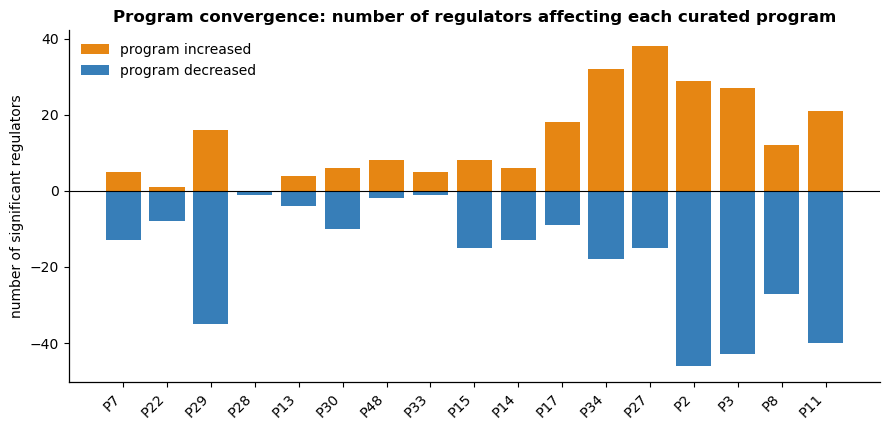

saved: outputs_program_first_advanced/target_set_convergence_program_dotplot.png
saved: outputs_program_first_advanced/target_set_convergence_program_dotplot.pdf
saved: outputs_program_first_advanced/target_set_convergence_program_dotplot.svg


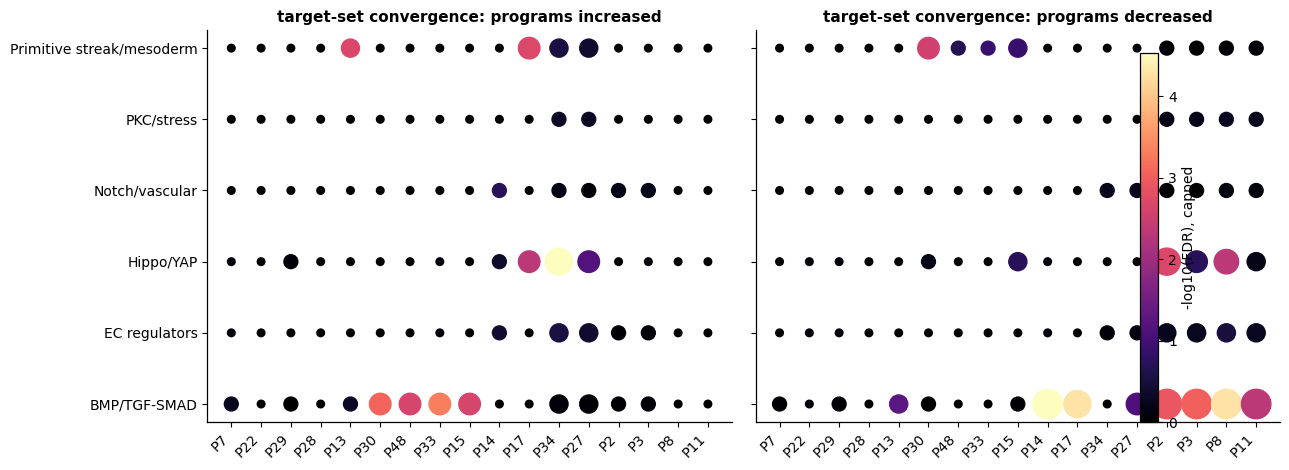

In [14]:
# Load custom target sets if available; otherwise use built-in sets.
TARGET_SETS = TARGET_SETS_BUILTIN.copy()
if CUSTOM_TARGET_SETS_CSV is not None and Path(CUSTOM_TARGET_SETS_CSV).exists():
    ts = pd.read_csv(CUSTOM_TARGET_SETS_CSV)
    set_col = pick_col(ts, ['target_set','set','pathway','group'], label='target set column')
    target_col_custom = pick_col(ts, ['target','gene','gene_symbol'], label='target gene column')
    custom_sets = ts.groupby(set_col)[target_col_custom].apply(lambda x: sorted(set(map(str, x)))).to_dict()
    TARGET_SETS.update(custom_sets)

# Significance by program and direction
sig_long = agg.copy()
sig_long['direction'] = np.where(sig_long['effect'] > 0, 'increased', 'decreased')
sig_long['is_sig'] = sig_long['fdr'] < FDR_CUTOFF

# Vulnerability / convergence count per program
conv_counts = (sig_long[sig_long['is_sig']]
               .groupby(['program_label','direction'])['target'].nunique()
               .reset_index(name='n_targets'))
conv_counts = conv_counts.merge(ann[['program_label','program_order','day','expert_annotation','program_group']], on='program_label', how='left')
conv_counts.to_csv(OUTDIR / 'program_convergence_counts_significant_targets.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4.4))
programs = program_order
x = np.arange(len(programs))
inc = conv_counts.query('direction == "increased"').set_index('program_label')['n_targets'].reindex(programs).fillna(0)
dec = conv_counts.query('direction == "decreased"').set_index('program_label')['n_targets'].reindex(programs).fillna(0)
ax.bar(x, inc, color='#E68613', label='program increased')
ax.bar(x, -dec, color='#377EB8', label='program decreased')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(programs, rotation=45, ha='right')
ax.set_ylabel('number of significant regulators')
ax.set_title('Program convergence: number of regulators affecting each curated program', fontsize=12, weight='bold')
ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, 'program_convergence_counts_barplot')
plt.show()

# Pathway/target-set convergence dot plot
universe_targets = set(sig_long['target'].unique())
N = len(universe_targets)
rows = []
for set_name, genes in TARGET_SETS.items():
    genes = set([g for g in genes if g in universe_targets])
    K = len(genes)
    for p in program_order:
        for direction in ['increased','decreased']:
            affected = set(sig_long[(sig_long['program_label']==p) & (sig_long['direction']==direction) & (sig_long['is_sig'])]['target'])
            n = len(affected)
            k = len(affected & genes)
            pv = fisher_overlap(k, K, n, N)
            # mean effect among target-set genes for this program, direction independent
            subeff = sig_long[(sig_long['program_label']==p) & (sig_long['target'].isin(genes))]['effect']
            rows.append({'target_set':set_name,'program_label':p,'direction':direction,'overlap_n':k,'affected_n':n,'set_size':K,'p_value':pv,'mean_effect_in_set':subeff.mean() if len(subeff) else np.nan})
conv_set = pd.DataFrame(rows)
conv_set['fdr'] = bh_fdr(conv_set['p_value'])
conv_set['neglog10_fdr'] = -np.log10(conv_set['fdr'].clip(lower=1e-300))
conv_set.to_csv(OUTDIR / 'target_set_convergence_by_program.csv', index=False)

# Plot dotplot for both directions, focusing on built-in sets
plot_df = conv_set.copy()
plot_df['program_order'] = plot_df['program_label'].map({p:i for i,p in enumerate(program_order)})
plot_df = plot_df[plot_df['set_size'] > 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, direction in zip(axes, ['increased','decreased']):
    sub = plot_df[plot_df['direction']==direction].copy()
    xlabels = program_order
    ylabels = sorted(sub['target_set'].unique())
    xmap = {p:i for i,p in enumerate(xlabels)}
    ymap = {s:i for i,s in enumerate(ylabels)}
    sizes = 30 + 70*np.minimum(sub['overlap_n'], 6)
    colors = np.minimum(sub['neglog10_fdr'], 8)
    sc = ax.scatter(sub['program_label'].map(xmap), sub['target_set'].map(ymap), s=sizes, c=colors, cmap='magma', vmin=0, vmax=max(2, colors.max()))
    ax.set_xticks(range(len(xlabels)))
    ax.set_xticklabels(xlabels, rotation=45, ha='right')
    ax.set_yticks(range(len(ylabels)))
    ax.set_yticklabels(ylabels)
    ax.set_title(f'target-set convergence: programs {direction}', fontsize=11, weight='bold')
fig.colorbar(sc, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02, label='-log10(FDR), capped')
fig.tight_layout()
savefig(fig, 'target_set_convergence_program_dotplot')
plt.show()

## 9. First affected day, persistence, and transience

This is a program-defined temporal summary. It uses only curated program effects and their annotated days.

,target,first_affected_day,n_days_affected,max_sig_programs_any_day
0,ACAA1,D3,1,2
1,ACTL7B,D3,1,1
2,ACVR1B,D1,2,4
3,ACVR2A,D2,2,4
4,ACVR2B,D2,2,2


saved: outputs_program_first_advanced/first_affected_day_barplot.png
saved: outputs_program_first_advanced/first_affected_day_barplot.pdf
saved: outputs_program_first_advanced/first_affected_day_barplot.svg


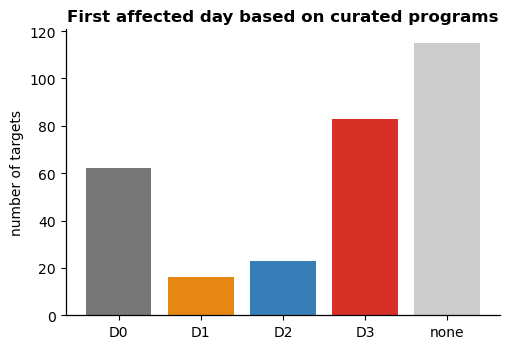

saved: outputs_program_first_advanced/target_by_day_significant_effect_binary_heatmap.png
saved: outputs_program_first_advanced/target_by_day_significant_effect_binary_heatmap.pdf
saved: outputs_program_first_advanced/target_by_day_significant_effect_binary_heatmap.svg


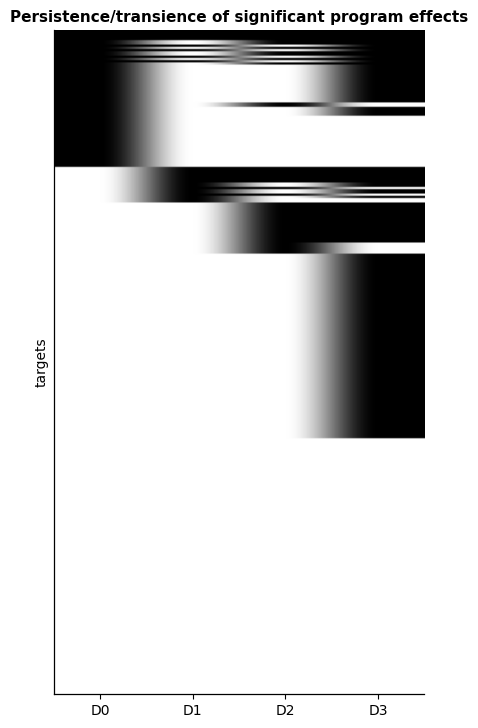

In [15]:
# Per-target day summaries
cur_day = agg.copy()
cur_day['is_sig'] = cur_day['fdr'] < FDR_CUTOFF

day_summary = (cur_day.groupby(['target','day'], as_index=False)
               .agg(any_sig=('is_sig','any'),
                    n_sig_programs=('is_sig','sum'),
                    strongest_abs_effect=('effect', lambda x: np.nanmax(np.abs(x))),
                    strongest_pos_effect=('effect','max'),
                    strongest_neg_effect=('effect','min')))

def first_day_for_target(sub):
    sig_days = sub[sub['any_sig']]['day'].tolist()
    if not sig_days:
        return 'none'
    return sorted(sig_days, key=lambda d:int(str(d).replace('D','')))[0]

first_day = day_summary.groupby('target').apply(first_day_for_target).reset_index(name='first_affected_day')
persistence = (day_summary.groupby('target', as_index=False)
               .agg(n_days_affected=('any_sig','sum'), max_sig_programs_any_day=('n_sig_programs','max')))
temporal_summary = first_day.merge(persistence, on='target', how='left')
temporal_summary.to_csv(OUTDIR / 'target_first_affected_day_and_persistence.csv', index=False)
display(temporal_summary.head())

# Count plot
order_days = ['D0','D1','D2','D3','none']
counts = temporal_summary['first_affected_day'].value_counts().reindex(order_days).fillna(0)
fig, ax = plt.subplots(figsize=(5.2,3.6))
ax.bar(counts.index, counts.values, color=['#777777','#E68613','#377EB8','#D73027','#CCCCCC'])
ax.set_ylabel('number of targets')
ax.set_title('First affected day based on curated programs', fontsize=12, weight='bold')
fig.tight_layout()
savefig(fig, 'first_affected_day_barplot')
plt.show()

# target × day binary/persistence heatmap
bin_mat = day_summary.pivot(index='target', columns='day', values='any_sig').reindex(columns=['D0','D1','D2','D3']).fillna(False).astype(int)
# order by first day and persistence
order_df = temporal_summary.set_index('target').reindex(bin_mat.index)
order_df['first_order'] = order_df['first_affected_day'].map({d:i for i,d in enumerate(order_days)})
order_df = order_df.sort_values(['first_order','n_days_affected'], ascending=[True,False])
bin_mat = bin_mat.loc[order_df.index]
fig, ax = plt.subplots(figsize=(4.2, max(5, 0.018*len(bin_mat)+2)))
im = ax.imshow(bin_mat.values, aspect='auto', cmap='Greys', vmin=0, vmax=1)
ax.set_xticks(range(bin_mat.shape[1]))
ax.set_xticklabels(bin_mat.columns)
ax.set_yticks([])
ax.set_ylabel('targets')
ax.set_title('Persistence/transience of significant program effects', fontsize=11, weight='bold')
fig.tight_layout()
savefig(fig, 'target_by_day_significant_effect_binary_heatmap')
plt.show()

## 10. Target modules, specificity, and asynchrony-like spread metrics

This clusters targets by raw curated-program effect profiles. It also calculates simple summary statistics:

- **specificity**: largest absolute program effect divided by total absolute effect
- **spread/asynchrony-like score**: standard deviation of effects across curated programs
- **n significant programs**: how broadly a target perturbs curated programs

These are descriptive target-fingerprint metrics, not pseudotime.

saved: outputs_program_first_advanced/target_module_clustering_curated_program_effects.png
saved: outputs_program_first_advanced/target_module_clustering_curated_program_effects.pdf
saved: outputs_program_first_advanced/target_module_clustering_curated_program_effects.svg


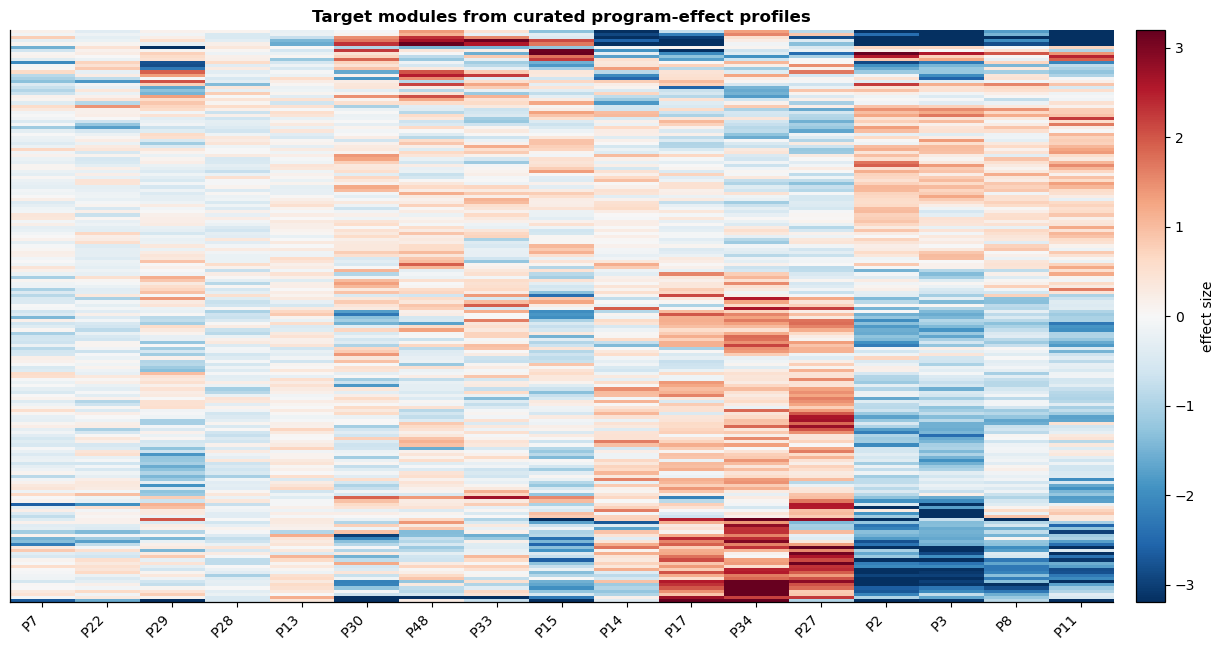

saved: outputs_program_first_advanced/target_specificity_vs_effect_spread_scatter.png
saved: outputs_program_first_advanced/target_specificity_vs_effect_spread_scatter.pdf
saved: outputs_program_first_advanced/target_specificity_vs_effect_spread_scatter.svg


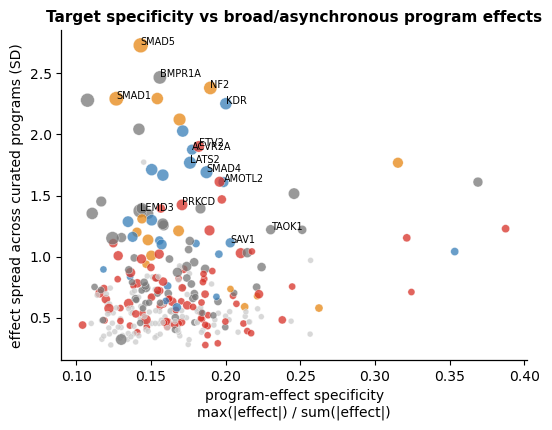

In [16]:
# target modules based on raw curated program effects
mat = effect_mat[program_order].copy()
# use targets with at least one significant curated effect or top 200 by effect
sig_any = (fdr_mat[program_order] < FDR_CUTOFF).any(axis=1)
module_targets = sig_any[sig_any].index.tolist()
if len(module_targets) < 20:
    module_targets = mat.abs().max(axis=1).sort_values(ascending=False).head(200).index.tolist()
mat_mod = mat.loc[module_targets].fillna(0)

# cluster rows
row_order = leaves_list(linkage(pdist(mat_mod.values, metric='euclidean'), method='average')) if len(mat_mod) > 2 else np.arange(len(mat_mod))
mat_mod = mat_mod.iloc[row_order]

vmax = np.nanquantile(np.abs(mat_mod.values), 0.98)
vmax = max(vmax, 0.25)
fig, ax = plt.subplots(figsize=(max(8,0.55*len(program_order)+3), max(5,0.025*len(mat_mod)+2)))
im = ax.imshow(mat_mod.values, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(program_order)))
ax.set_xticklabels(program_order, rotation=45, ha='right')
ax.set_yticks([])
ax.set_title('Target modules from curated program-effect profiles', fontsize=12, weight='bold')
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label='effect size')
fig.tight_layout()
savefig(fig, 'target_module_clustering_curated_program_effects')
plt.show()

# summary metrics
abs_sum = mat.abs().sum(axis=1)
max_abs = mat.abs().max(axis=1)
specificity = max_abs / abs_sum.replace(0, np.nan)
spread = mat.std(axis=1, skipna=True)
n_sig = (fdr_mat[program_order] < FDR_CUTOFF).sum(axis=1)
metrics = pd.DataFrame({'target': mat.index, 'max_abs_effect': max_abs, 'sum_abs_effect': abs_sum, 'specificity': specificity, 'effect_spread_sd': spread, 'n_significant_programs': n_sig}).reset_index(drop=True)
metrics = metrics.merge(temporal_summary, on='target', how='left')
metrics.to_csv(OUTDIR / 'target_specificity_asynchrony_spread_metrics.csv', index=False)

fig, ax = plt.subplots(figsize=(5.6,4.4))
colors = metrics['first_affected_day'].map({'D0':'#777777','D1':'#E68613','D2':'#377EB8','D3':'#D73027','none':'#CCCCCC'}).fillna('#CCCCCC')
ax.scatter(metrics['specificity'], metrics['effect_spread_sd'], s=18+8*metrics['n_significant_programs'], c=colors, alpha=0.75, edgecolors='white', linewidth=0.3)
for t in SELECTED_TARGETS_FOR_CARDS:
    row = metrics[metrics['target']==t]
    if len(row):
        ax.text(row['specificity'].iloc[0], row['effect_spread_sd'].iloc[0], t, fontsize=7)
ax.set_xlabel('program-effect specificity\nmax(|effect|) / sum(|effect|)')
ax.set_ylabel('effect spread across curated programs (SD)')
ax.set_title('Target specificity vs broad/asynchronous program effects', fontsize=11, weight='bold')
fig.tight_layout()
savefig(fig, 'target_specificity_vs_effect_spread_scatter')
plt.show()

## 11. Optional: neighborhood vulnerability map

This section is optional because it requires neighborhood-level enrichment files. It is included so you can try the idea later without mixing clusters into the main program interpretation.

Required file styles can vary. The code below tries to infer columns such as target, log2OR/enrichment, FDR, x/y coordinates, and neighborhood ID.

In [17]:
if NEIGHBORHOOD_ENRICHMENT_CSV is None or not Path(NEIGHBORHOOD_ENRICHMENT_CSV).exists():
    print('Skipping neighborhood vulnerability map: set NEIGHBORHOOD_ENRICHMENT_CSV and optionally NEIGHBORHOOD_COORDINATES_CSV in the config cell.')
else:
    neigh = pd.read_csv(NEIGHBORHOOD_ENRICHMENT_CSV)
    print('Neighborhood enrichment columns:', list(neigh.columns))
    target_c = pick_col(neigh, ['target','target_name','gene'], label='target column')
    nb_c = pick_col(neigh, ['neighborhood_id','neighborhood','seed_cell','cell_id','index'], label='neighborhood id column')
    fdr_c = pick_col(neigh, ['fdr','padj','p_value_corrected','qval'], required=False, label='FDR column')
    eff_c = pick_col(neigh, ['log2OR','log2_or','enrichment','effect','score'], required=False, label='enrichment/effect column')
    if fdr_c is None:
        neigh['is_sig'] = True
    else:
        neigh['is_sig'] = neigh[fdr_c] < FDR_CUTOFF
    if eff_c is None:
        neigh['direction'] = 'affected'
    else:
        neigh['direction'] = np.where(neigh[eff_c] > 0, 'enriched', 'depleted')
    vul = (neigh[neigh['is_sig']]
           .groupby(nb_c)
           .agg(n_targets_affected=(target_c,'nunique'),
                n_enriched=('direction', lambda x: np.sum(np.array(x)=='enriched')),
                n_depleted=('direction', lambda x: np.sum(np.array(x)=='depleted')))
           .reset_index())
    vul.to_csv(OUTDIR / 'neighborhood_vulnerability_scores.csv', index=False)
    display(vul.head())

    if NEIGHBORHOOD_COORDINATES_CSV is not None and Path(NEIGHBORHOOD_COORDINATES_CSV).exists():
        coords = pd.read_csv(NEIGHBORHOOD_COORDINATES_CSV)
        x_c = pick_col(coords, ['umap1','UMAP1','x','X_umap1','UMAP_1'], label='x/umap1 column')
        y_c = pick_col(coords, ['umap2','UMAP2','y','X_umap2','UMAP_2'], label='y/umap2 column')
        nb2_c = pick_col(coords, [nb_c,'neighborhood_id','neighborhood','seed_cell','cell_id','index'], label='neighborhood id column in coords')
        plot = coords.merge(vul, left_on=nb2_c, right_on=nb_c, how='left')
        plot['n_targets_affected'] = plot['n_targets_affected'].fillna(0)
        fig, ax = plt.subplots(figsize=(5,4.5))
        sc = ax.scatter(plot[x_c], plot[y_c], c=plot['n_targets_affected'], s=8, cmap='magma', alpha=0.85, edgecolors='none')
        ax.set_title('Neighborhood vulnerability: number of targets affecting neighborhood', fontsize=11, weight='bold')
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02, label='n affected targets')
        fig.tight_layout()
        savefig(fig, 'neighborhood_vulnerability_umap')
        plt.show()

Skipping neighborhood vulnerability map: set NEIGHBORHOOD_ENRICHMENT_CSV and optionally NEIGHBORHOOD_COORDINATES_CSV in the config cell.


## 12. Optional: cross-screen concordance by program phenotype class

If you provide a genome-wide screen table, this section can test whether specific program phenotypes explain genome-wide CDH5+ vs CDH5− enrichment. This is optional and not required for the core program-first figures.

In [18]:
if GENOME_WIDE_SCREEN_CSV is None or not Path(GENOME_WIDE_SCREEN_CSV).exists():
    print('Skipping cross-screen concordance: set GENOME_WIDE_SCREEN_CSV in the config cell.')
else:
    screen = pd.read_csv(GENOME_WIDE_SCREEN_CSV, sep=None, engine='python')
    print('Screen columns:', list(screen.columns))
    scr_target_col = pick_col(screen, ['target','Target','gene','target_name'], label='screen target column')
    scr_effect_col = pick_col(screen, ['log2FC','log2_fold_change','effect','score'], label='screen effect column')
    screen = screen.rename(columns={scr_target_col:'target', scr_effect_col:'screen_effect'})
    # Merge with target metrics and color by first affected day.
    tmp = metrics.merge(screen[['target','screen_effect']], on='target', how='inner')
    print('Matched targets:', len(tmp))
    fig, ax = plt.subplots(figsize=(5.5,4.2))
    colors = tmp['first_affected_day'].map({'D0':'#777777','D1':'#E68613','D2':'#377EB8','D3':'#D73027','none':'#CCCCCC'}).fillna('#CCCCCC')
    ax.scatter(tmp['screen_effect'], tmp['max_abs_effect'], c=colors, s=28, alpha=0.75, edgecolors='white', linewidth=0.3)
    r,p = stats.pearsonr(tmp['screen_effect'], tmp['max_abs_effect'])
    ax.set_xlabel('genome-wide screen effect')
    ax.set_ylabel('max abs curated-program effect')
    ax.set_title(f'Cross-screen concordance by program impact\nr={r:.2f}', fontsize=11, weight='bold')
    fig.tight_layout()
    savefig(fig, 'cross_screen_concordance_program_impact')
    plt.show()

Skipping cross-screen concordance: set GENOME_WIDE_SCREEN_CSV in the config cell.


## 13. Package outputs

In [19]:
# Package output files from this notebook.
import zipfile
zip_path = Path('outputs_program_first_advanced.zip')
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for fp in OUTDIR.rglob('*'):
        if fp.is_file():
            z.write(fp, arcname=str(fp.relative_to(OUTDIR)))
print('Packaged outputs:', zip_path.resolve())

Packaged outputs: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/program_first_advanced_analyses_notebook_package/outputs_program_first_advanced.zip
